In [7]:

import os
import glob
import gc
import time
import psutil
import pandas as pd
import matplotlib.pyplot as plt
import dask.dataframe as dd

print("Libraries imported successfully.")


Libraries imported successfully.


In [8]:


folder = "/kaggle/input/datasets/yuanyuwendymu/airline-delay-and-cancellation-data-2009-2018"

file_paths = sorted(glob.glob(folder + "/*.csv"))

total_bytes = sum(os.path.getsize(f) for f in file_paths)
total_gb = total_bytes / (1024 ** 3)

print("Number of CSV files:", len(file_paths))
print(f"Total dataset size: {total_gb:.2f} GB")

for file in file_paths:
    print(
        os.path.basename(file),
        f"{os.path.getsize(file) / (1024**3):.2f} GB"
    )

assert len(file_paths) > 0, "No CSV files found!"

Number of CSV files: 10
Total dataset size: 7.10 GB
2009.csv 0.74 GB
2010.csv 0.74 GB
2011.csv 0.70 GB
2012.csv 0.72 GB
2013.csv 0.73 GB
2014.csv 0.67 GB
2015.csv 0.67 GB
2016.csv 0.65 GB
2017.csv 0.65 GB
2018.csv 0.83 GB


In [10]:

chunk_size = 100_000

total_rows = 0
total_sums = None
total_counts = None
max_ram_chunk = 0

process = psutil.Process(os.getpid())
start = time.time()

for file in file_paths:
    print("Processing:", os.path.basename(file))

    for chunk in pd.read_csv(
        file,
        chunksize=chunk_size,
        dtype={"CANCELLATION_CODE": "object"}
    ):
        total_rows += len(chunk)

        numeric = chunk.select_dtypes(include="number")

        chunk_sums = numeric.sum()
        chunk_counts = numeric.count()

        if total_sums is None:
            total_sums = chunk_sums
            total_counts = chunk_counts
        else:
            total_sums = total_sums.add(
                chunk_sums, fill_value=0
            )
            total_counts = total_counts.add(
                chunk_counts, fill_value=0
            )

        ram = process.memory_info().rss / (1024**3)
        max_ram_chunk = max(max_ram_chunk, ram)

        del chunk, numeric
        gc.collect()

elapsed_chunk = time.time() - start

if total_sums is not None:
    global_means = total_sums / total_counts.replace(
        0, float("nan")
    )

    print("\nGlobal means:")
    print(global_means)

print("\nTotal rows processed:", total_rows)
print("Execution time:", round(elapsed_chunk, 2), "seconds")
print("Maximum observed process RAM:",
      round(max_ram_chunk, 2), "GB")

Processing: 2009.csv
Processing: 2010.csv
Processing: 2011.csv
Processing: 2012.csv
Processing: 2013.csv
Processing: 2014.csv
Processing: 2015.csv
Processing: 2016.csv
Processing: 2017.csv
Processing: 2018.csv

Global means:
OP_CARRIER_FL_NUM      2300.241257
CRS_DEP_TIME           1327.202589
DEP_TIME               1333.141072
DEP_DELAY                 9.044879
TAXI_OUT                 15.991963
WHEELS_OFF             1356.017721
WHEELS_ON              1473.756664
TAXI_IN                   7.118817
CRS_ARR_TIME           1495.146887
ARR_TIME               1479.336885
ARR_DELAY                 4.700336
CANCELLED                 0.015810
DIVERTED                  0.002365
CRS_ELAPSED_TIME        136.956423
ACTUAL_ELAPSED_TIME     132.876620
AIR_TIME                109.776974
DISTANCE                786.676109
CARRIER_DELAY            17.820560
WEATHER_DELAY             2.657591
NAS_DELAY                14.403737
SECURITY_DELAY            0.078529
LATE_AIRCRAFT_DELAY      23.283611
Unnam

In [11]:

start = time.time()

ddf = dd.read_csv(
    file_paths,
    dtype={"CANCELLATION_CODE": "object"},
    assume_missing=True
)

print("Dask DataFrame:")
print(ddf)

print("\nColumns:")
print(ddf.columns.tolist())

numeric_columns = ddf.select_dtypes(
    include="number"
).columns.tolist()

print("\nNumber of numeric columns:", len(numeric_columns))

if numeric_columns:
    means_dask = ddf[numeric_columns].mean().compute()

    print("\nGlobal means:")
    print(means_dask)

elapsed_dask = time.time() - start

print("\nExecution time:", round(elapsed_dask, 2), "seconds")
print(
    "Process RAM after computation:",
    round(psutil.Process(os.getpid()).memory_info().rss / (1024**3), 2),
    "GB"
)

Dask DataFrame:
Dask DataFrame Structure:
                FL_DATE OP_CARRIER OP_CARRIER_FL_NUM  ORIGIN    DEST CRS_DEP_TIME DEP_TIME DEP_DELAY TAXI_OUT WHEELS_OFF WHEELS_ON  TAXI_IN CRS_ARR_TIME ARR_TIME ARR_DELAY CANCELLED CANCELLATION_CODE DIVERTED CRS_ELAPSED_TIME ACTUAL_ELAPSED_TIME AIR_TIME DISTANCE CARRIER_DELAY WEATHER_DELAY NAS_DELAY SECURITY_DELAY LATE_AIRCRAFT_DELAY Unnamed: 27
npartitions=114                                                                                                                                                                                                                                                                                                                                             
                 string     string           float64  string  string      float64  float64   float64  float64    float64   float64  float64      float64  float64   float64   float64            string  float64          float64             float64  float64  floa

In [20]:
import os
import time
import psutil
import pandas as pd

process = psutil.Process(os.getpid())

file_path = file_paths[0]

ram_before = process.memory_info().rss / (1024 ** 3)

start_time = time.time()

df_normal = pd.read_csv(
    file_path,
    dtype={"CANCELLATION_CODE": "object"},
    low_memory=False
)

elapsed_normal = time.time() - start_time

ram_after = process.memory_info().rss / (1024 ** 3)

ram_normal = max(0, ram_after - ram_before)

print("Pandas Normal")
print("Rows:", len(df_normal))
print(f"Execution Time: {elapsed_normal:.2f} seconds")
print(f"RAM Increase: {ram_normal:.3f} GB")
print(f"File Size: {os.path.getsize(file_path) / (1024**3):.2f} GB")

Pandas Normal
Rows: 6429338
Execution Time: 27.94 seconds
RAM Increase: 1.341 GB
File Size: 0.74 GB


         Method  Dataset Size (GB)  Execution Time (seconds)  Observed RAM (GB)
  Pandas Normal           0.738175                 27.944928           1.341328
Pandas Chunking           7.101233                289.453716           2.548725
 Dask DataFrame           7.101233                 66.571379           4.977150


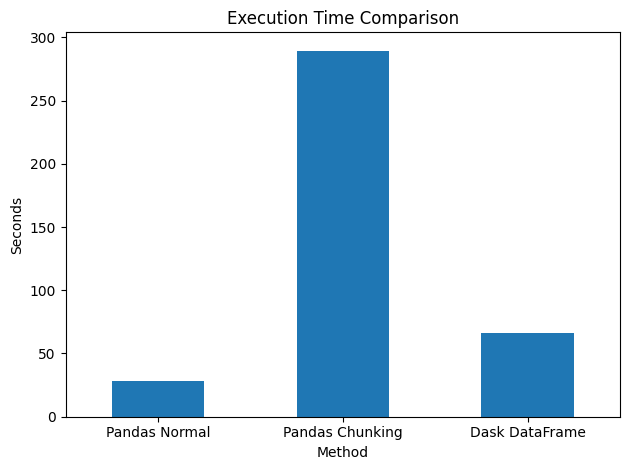

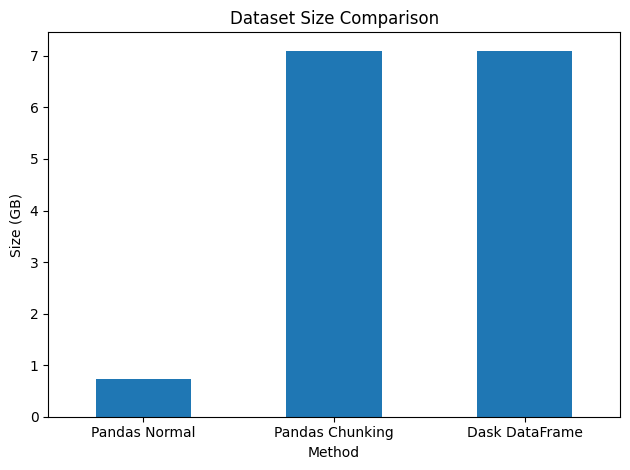

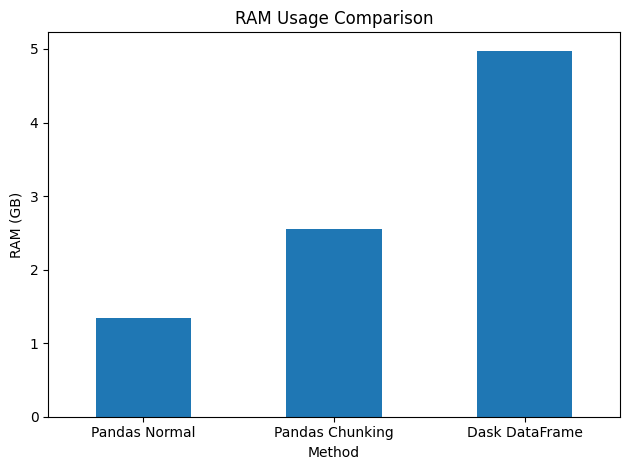

In [21]:
import matplotlib.pyplot as plt
import pandas as pd

results = pd.DataFrame({
    "Method": [
        "Pandas Normal",
        "Pandas Chunking",
        "Dask DataFrame"
    ],
    "Dataset Size (GB)": [
        os.path.getsize(file_paths[0]) / (1024**3),
        total_gb,
        total_gb
    ],
    "Execution Time (seconds)": [
        elapsed_normal,
        elapsed_chunk,
        elapsed_dask
    ],
    "Observed RAM (GB)": [
        ram_normal,
        max_ram_chunk,
        psutil.Process(os.getpid()).memory_info().rss / (1024**3)
    ]
})

print(results.to_string(index=False))

# Execution time comparison
results.plot(
    x="Method",
    y="Execution Time (seconds)",
    kind="bar",
    legend=False
)
plt.title("Execution Time Comparison")
plt.ylabel("Seconds")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# Dataset size comparison
results.plot(
    x="Method",
    y="Dataset Size (GB)",
    kind="bar",
    legend=False
)
plt.title("Dataset Size Comparison")
plt.ylabel("Size (GB)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# RAM comparison
results.plot(
    x="Method",
    y="Observed RAM (GB)",
    kind="bar",
    legend=False
)
plt.title("RAM Usage Comparison")
plt.ylabel("RAM (GB)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()